# 01 · Text similarity benchmark and threshold calibration

**Question.** How well do S-Way's text-similarity measures separate documents that share copied or reworded passages from documents that do not, and which decision thresholds should the evidence-fusion labels (*Moderate* / *High*) use?

**Data.** Public-domain passages from Project Gutenberg (NLTK selection). Synthetic "submissions" are built by inserting a known fraction of one passage — verbatim or with rule-based paraphrasing — into unrelated text. Because the copied fraction is known exactly, precision and recall can be measured.

**Engine.** Every comparison is computed by the shipped JavaScript engine (`js/engines/text-similarity.js`) via `tools/sway-cli.mjs`.

**Limitations.** Rule-based paraphrases are milder than human rewriting; real assignments share topic vocabulary more than random book passages do. Treat the thresholds as starting values, not validated operating points.

In [1]:
import sys, json, random, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
%matplotlib inline
sys.path.insert(0, '.')
from sway_research import *
RESULTS = DATA / 'results'; RESULTS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 90, 'font.family': 'monospace', 'axes.facecolor': '#EDE3CC', 'figure.facecolor': '#F4ECD9'})
pd.set_option('display.width', 140)

In [2]:
rng = random.Random(2026)
books = sorted(p.name for p in GUT.glob('*.txt'))
sents = {b: sentences(load_book(b)) for b in books}
books = [b for b in books if len(sents[b]) > 600]   # poetry collections are too short for 300-word samples
pd.DataFrame({'sentences': {b: len(s) for b, s in sents.items()}}).T

,austen-emma.txt,austen-persuasion.txt,austen-sense.txt,bible-kjv.txt,blake-poems.txt,bryant-stories.txt,burgess-busterbrown.txt,carroll-alice.txt,chesterton-ball.txt,chesterton-brown.txt,chesterton-thursday.txt,edgeworth-parents.txt,melville-moby_dick.txt,milton-paradise.txt,shakespeare-caesar.txt,shakespeare-hamlet.txt,shakespeare-macbeth.txt,whitman-leaves.txt
sentences,5674,2556,3484,480,273,1863,778,759,3374,2690,2621,5719,6553,1094,919,1262,794,1713


In [3]:
def sample(book, words=300):
    s = sents[book]
    return passage(s, rng.randrange(0, len(s) - 300), words)

cases = []
for _ in range(50):                                   # negatives: unrelated books
    b1, b2 = rng.sample(books, 2)
    cases.append(dict(kind='unrelated', frac=0.0, para=False, a=' '.join(sample(b1)), b=' '.join(sample(b2))))
for _ in range(40):                                   # negatives: same book, different passages (shared topic & style)
    b = rng.choice([x for x in books if len(sents[x]) > 2000])
    cases.append(dict(kind='same book, other passage', frac=0.0, para=False, a=' '.join(sample(b)), b=' '.join(sample(b))))
for frac in [0.1, 0.2, 0.3, 0.5, 0.8]:
    for para in (False, True):
        for _ in range(16):
            b1, b2 = rng.sample(books, 2)
            A, filler = sample(b1), sample(b2, 320)
            m = max(1, round(frac * len(filler)))
            start = rng.randrange(0, max(1, len(A) - m + 1))
            block = A[start:start + m]
            if para:
                block = [paraphrase(s, rng) for s in block]
            keep = filler[: max(1, len(filler) - len(block))]
            pos = rng.randrange(0, len(keep) + 1)
            B = keep[:pos] + block + keep[pos:]
            true_frac = sum(len(s.split()) for s in block) / sum(len(s.split()) for s in B)
            cases.append(dict(kind='paraphrased copy' if para else 'verbatim copy', frac=frac, true_frac=true_frac, para=para, a=' '.join(A), b=' '.join(B)))
len(cases)

250

In [4]:
res = run_js([{'op': 'text', 'a': c['a'], 'b': c['b']} for c in cases])
rows = []
for c, r in zip(cases, res):
    m = r['metrics']
    rows.append(dict(kind=c['kind'], frac=c['frac'], para=c['para'],
        coverage=max(m['sharedPassageCoverageA'], m['sharedPassageCoverageB']),
        containment=max(m['ngram5ContainmentAinB'], m['ngram5ContainmentBinA']),
        sentence_rate=max(m['sentenceMatchRateA'], 0), paraphrase_rate=m['paraphraseRateA'], tfidf=m['tfidfCosine'],
        char_cos=m['charTrigramCosine']))
df = pd.DataFrame(rows)
df.groupby(['kind', 'frac'])[['coverage', 'containment', 'paraphrase_rate', 'tfidf']].mean().round(3)

coverage  containment  paraphrase_rate  tfidf
kind                     frac                                               
paraphrased copy         0.1      0.100        0.083            0.013  0.106
                         0.2      0.206        0.167            0.019  0.174
                         0.3      0.252        0.202            0.045  0.224
                         0.5      0.428        0.365            0.034  0.376
                         0.8      0.678        0.566            0.109  0.646
same book, other passage 0.0      0.000        0.000            0.000  0.076
unrelated                0.0      0.000        0.000            0.000  0.039
verbatim copy            0.1      0.121        0.107            0.027  0.118
                         0.2      0.209        0.198            0.021  0.159
                         0.3      0.328        0.320            0.015  0.250
                         0.5      0.548        0.542            0.022  0.428
                         0.8      0.884        0.882            0.000  0.731

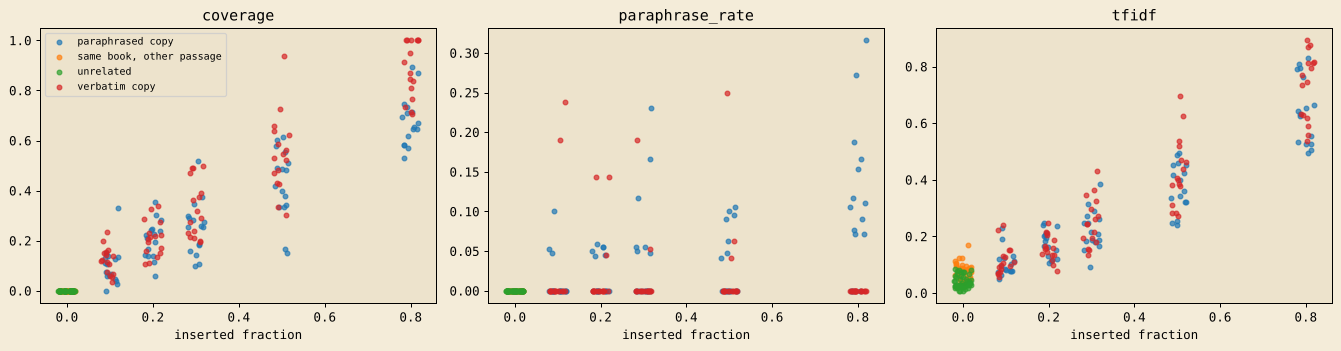

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['coverage', 'paraphrase_rate', 'tfidf']):
    for kind, g in df.groupby('kind'):
        ax.scatter(g['frac'] + np.random.uniform(-.02, .02, len(g)), g[col], label=kind, s=14, alpha=.7)
    ax.set_title(col); ax.set_xlabel('inserted fraction')
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Calibrating the *Moderate* label

A pair is labelled at least *Moderate* when **any** of: shared-passage coverage ≥ `modCoverage`, 5-gram containment ≥ `modContainment`, possible-paraphrase rate ≥ `modParaphrase`, TF-IDF cosine ≥ `modTfidf`. Positives are all pairs with inserted material (≥ 10 %). The grid search maximises recall subject to a false-positive rate of at most 2 % on the negatives — false alarms are the costlier error for a screening tool.

In [6]:
neg = df[df.frac == 0]; pos = df[df.frac > 0]
def moderate(d, t):
    return (d.coverage >= t[0]) | (d.containment >= t[1]) | (d.paraphrase_rate >= t[2]) | (d.tfidf >= t[3])
best = None
for c in [0.03, 0.05, 0.08, 0.1, 0.12]:
    for k in [0.05, 0.1, 0.15, 0.2]:
        for p in [0.1, 0.15, 0.2, 0.25, 0.3, 0.4]:
            for t in [0.4, 0.5, 0.6, 0.7, 0.8, 1.01]:
                fpr = moderate(neg, (c, k, p, t)).mean(); rec = moderate(pos, (c, k, p, t)).mean()
                # among threshold sets with the best recall, keep the most conservative (largest) ones:
                # the benchmark's negatives share no phrases at all, so lower values would be untested optimism
                cons = c / 0.12 + k / 0.2 + p / 0.4 + min(t, 1) / 1.0
                if fpr <= 0.02 and (best is None or rec > best[0] + 1e-9 or (abs(rec - best[0]) < 1e-9 and cons > best[3])):
                    best = (rec, fpr, (c, k, p, t), cons)
rec, fpr, MOD, _ = best
print(f'Moderate thresholds coverage≥{MOD[0]} containment≥{MOD[1]} paraphrase≥{MOD[2]} tfidf≥{MOD[3]}  →  recall {rec:.2%}, FPR {fpr:.2%}')

Moderate thresholds coverage≥0.03 containment≥0.2 paraphrase≥0.4 tfidf≥1.01  →  recall 98.75%, FPR 0.00%


In [7]:
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
y = (df.frac > 0).astype(int); yhat = moderate(df, MOD).astype(int)
p, r, f, _ = precision_recall_fscore_support(y, yhat, average='binary')
print('confusion matrix [[TN FP] [FN TP]]:'); print(confusion_matrix(y, yhat))
print(f'precision {p:.3f}  recall {r:.3f}  F1 {f:.3f}')
df['moderate'] = yhat
df[df.frac > 0].groupby(['kind', 'frac'])['moderate'].mean().unstack(0).round(2)

confusion matrix [[TN FP] [FN TP]]:
[[ 90   0]
 [  2 158]]
precision 1.000  recall 0.988  F1 0.994


kind,paraphrased copy,verbatim copy
frac,,
0.1,0.88,1.0
0.2,1.00,1.0
0.3,1.00,1.0
0.5,1.00,1.0
0.8,1.00,1.0


## Calibrating the *High* label

*High* should mean "a substantial part of one document is shared verbatim or near-verbatim". Positives: verbatim insertions of ≥ 30 %. Everything else (including paraphrased insertions and smaller copies) counts as negative here, so *High* stays conservative.

In [8]:
def high(d, t):
    return (d.coverage >= t[0]) | (d.containment >= t[1]) | (d.sentence_rate >= t[2])
posH = df[(df.frac >= 0.3) & (~df.para)]; negH = df.drop(posH.index)
bestH = None
for c in [0.2, 0.25, 0.3, 0.35, 0.4]:
    for k in [0.3, 0.4, 0.5, 0.6]:
        for s in [0.2, 0.3, 0.4, 0.5]:
            fpr = high(negH[negH.frac < 0.2], (c, k, s)).mean()   # must not fire on small copies or negatives
            rec = high(posH, (c, k, s)).mean()
            if fpr <= 0.02 and (bestH is None or rec > bestH[0] + 1e-9 or (abs(rec - bestH[0]) < 1e-9 and c + k + s > sum(bestH[2]))):
                bestH = (rec, fpr, (c, k, s))
recH, fprH, HIGH = bestH
print(f'High thresholds coverage≥{HIGH[0]} containment≥{HIGH[1]} sentence-match≥{HIGH[2]} → recall {recH:.2%} on ≥30% verbatim, FPR {fprH:.2%} on <20%/negatives')

High thresholds coverage≥0.2 containment≥0.6 sentence-match≥0.3 → recall 100.00% on ≥30% verbatim, FPR 1.64% on <20%/negatives


## Error analysis

Which positives are missed at the *Moderate* level? Typically small paraphrased insertions — rule-based synonyms change enough character trigrams to fall below the paraphrase thresholds. This is the documented weakness of lexical paraphrase detection without an embedding model.

In [9]:
missed = df[(df.frac > 0) & (df.moderate == 0)]
print(f'{len(missed)} missed positives'); missed.groupby(['kind', 'frac']).size()

2 missed positives


kind              frac
paraphrased copy  0.1     2
dtype: int64

In [10]:
fp = df[(df.frac == 0) & (df.moderate == 1)]
print(f'{len(fp)} false positives'); fp[['kind', 'coverage', 'containment', 'paraphrase_rate', 'tfidf']]

0 false positives


,kind,coverage,containment,paraphrase_rate,tfidf


In [11]:
out = {'text_fusion': {'modCoverage': MOD[0], 'modContainment': MOD[1], 'modParaphrase': MOD[2], 'modTfidf': min(MOD[3], 1.0),
                          'highCoverage': HIGH[0], 'highContainment': HIGH[1], 'highSentenceRate': HIGH[2]},
       'metrics': {'moderate_precision': p, 'moderate_recall': r, 'moderate_f1': f, 'moderate_fpr': fpr, 'high_recall': recH, 'high_fpr': fprH, 'n_pairs': len(df)}}
(RESULTS / 'text.json').write_text(json.dumps(out, indent=2)); out

{'text_fusion': {'modCoverage': 0.03,
  'modContainment': 0.2,
  'modParaphrase': 0.4,
  'modTfidf': 1.0,
  'highCoverage': 0.2,
  'highContainment': 0.6,
  'highSentenceRate': 0.3},
 'metrics': {'moderate_precision': 1.0,
  'moderate_recall': 0.9875,
  'moderate_f1': 0.9937106918238994,
  'moderate_fpr': np.float64(0.0),
  'high_recall': np.float64(1.0),
  'high_fpr': np.float64(0.01639344262295082),
  'n_pairs': 250}}